<h1>Semi-Supervised Learning & Label Propagation</h1>

<h2> Introduction</h2>

Semi-supervised algorithms use labelled samples and the structure of unlabelled
measurements to estimate missing labels.

**Label Propagation** holds the supplied labels fixed during propagation.
**Label Spreading** uses a normalised graph and soft clamping, allowing the
supplied label information to be adjusted. Hard clamping applies to the fitted
graph distributions; a later `predict()` call uses neighbours' distributions
and is not guaranteed to reproduce every supplied label.

Here, Label Propagation uses a **KNN kernel** with `n_neighbors=5`.
The Label Spreading baseline uses its default **RBF kernel**.
This compares two configurations, not just two algorithms.

We use Iris and the same seeded label-hiding procedure as lab 5_b.
A 70% hiding probability produces 111 hidden labels (74.0%) and 39 retained
labels in this run. Both models use all measurements during fitting, so the
evaluation measures hidden-label recovery rather than performance on an
independent test set.

<h2> Comparison of Label Propagation and Label Spreading</h2>

| Aspect | Label Propagation | Label Spreading |
|---|---|---|
| Main idea | Propagates label information through a similarity graph | Spreads label information using a normalised graph and regularisation |
| Supplied labels during fitting | **Hard clamping:** keeps their label distributions fixed | **Soft clamping:** balances supplied labels with information from neighbours |
| Influence of neighbours on supplied labels | Cannot change their distributions during propagation | Controlled by `alpha`; higher values give neighbours more influence |
| Incorrect supplied labels | Remain fixed during propagation and may spread errors | Can be adjusted, which may help with noisy labels |
| Supported graph kernels | `rbf` and `knn` | `rbf` and `knn` |
| Kernel used in this notebook | `knn`, with `n_neighbors=5` for the baseline | Default `rbf`, with `gamma=20` |
| Prediction | Uses the fitted label distributions to predict classes | Uses the fitted label distributions to predict classes |
| Always better? | No—performance depends on the data and settings | No—flexibility does not guarantee better accuracy |

**Comparison note:** This notebook changes both the algorithm and the kernel.
To isolate the algorithm difference, use matching kernel settings and the same
labelled samples.

<h1>Step 1: Import the libraries</h1>

In [1]:
# import the libraries we need:
# numpy             -> random numbers and array handling
# datasets          -> sklearn's built-in datasets (includes Iris)
# LabelPropagation, LabelSpreading -> semi-supervised models to compare
# metrics           -> honest marking: accuracy, per-class report, confusion matrix
import numpy as np
from numpy.typing import ArrayLike, NDArray
from sklearn import datasets
from sklearn.semi_supervised import LabelPropagation, LabelSpreading
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold
import pandas as pd
from notebook_display import display_table

from week_5_semi_supervised_plots import (
    plot_iris,
    plot_prediction_results,
    plot_confusion_matrices,
    display_coloured_labels,
)

<h1>Step 2: Import the dataset</h1>

The Iris dataset is included in scikit-learn, so no separate dataset download is needed.

In [2]:
# load the Iris dataset
iris = datasets.load_iris()

# quick orientation: how many flowers, how many measurements, which species
print("data shape:", iris.data.shape)          # (150 flowers, 4 measurements)
print("species:", list(iris.target_names))     # 0=setosa, 1=versicolor, 2=virginica

data shape: (150, 4)
species: ['setosa', 'versicolor', 'virginica']


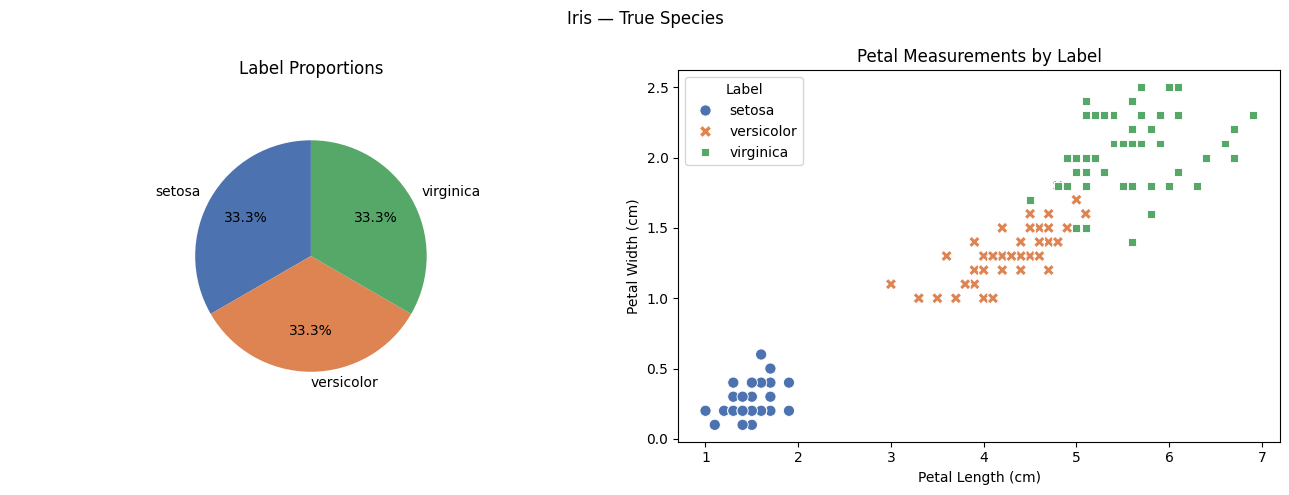

In [3]:
plot_iris(iris, title="Iris — True Species")

<h1>Step 3: Hide the labels</h1>

Each label has a 70% chance of being replaced with **-1**, scikit-learn's
marker for an unlabelled sample. Reinitialising the generator with seed 0
reproduces the same mask: 111 hidden labels and 39 retained labels.
This matches a fresh sequential run of the 70% experiment in lab 5_b.

In [4]:
# a random number generator with a fixed seed — same "random" choices every run
rand = np.random.RandomState(0)

# draw a random number 0-1 for each flower; True (about 70% of them) = hide its label
random_unlabeled_samples = rand.rand(len(iris.target)) <= 0.7

# copy the true labels, then overwrite the hidden ones with -1
# (we keep iris.target untouched — we need the truth later for marking)
un_labelled = np.copy(iris.target)
un_labelled[random_unlabeled_samples] = -1

# how did the split land?
print("total flowers:", len(un_labelled))
print("labels hidden:", random_unlabeled_samples.sum())
print("labels kept:  ", (~random_unlabeled_samples).sum())

total flowers: 150
labels hidden: 111
labels kept:   39


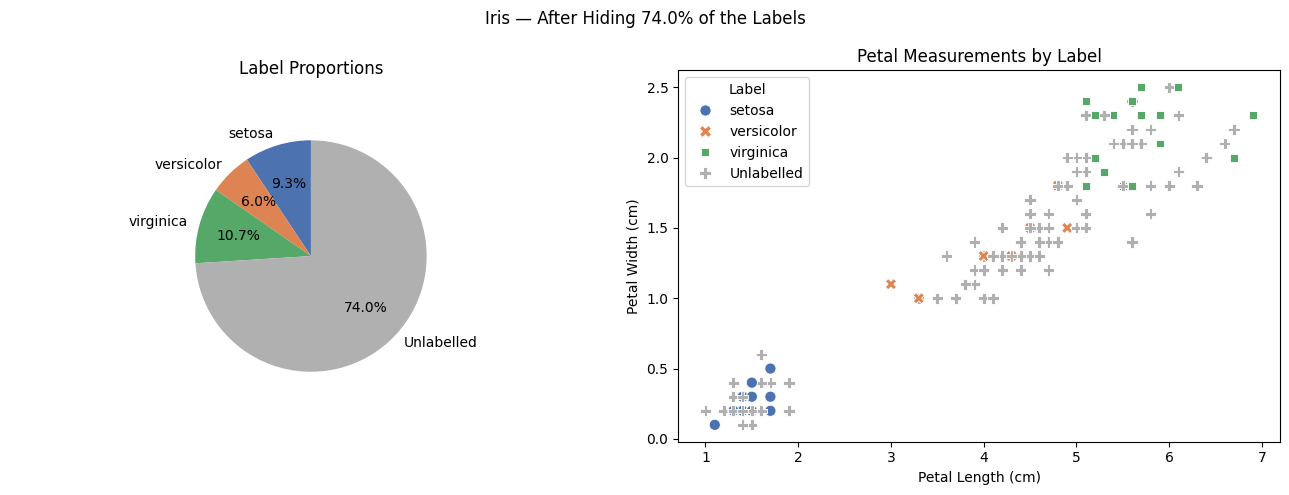

In [5]:
plot_iris(
    iris,
    labels=un_labelled,
    title=f"Iris — After Hiding {random_unlabeled_samples.mean():.1%} of the Labels",
)

<h2>Step 3.1: Inspect the labels</h2>

Every -1 below marks a flower whose species label is withheld from the model.

In [6]:
# Display the label array supplied to the model.

display_coloured_labels(
    un_labelled,
    n_classes=len(iris.target_names),
    max_per_row=24,  # Keep at most 24 labels on each row.
)

[-1  0 -1 -1 -1 -1 -1  0  0 -1  0 -1 -1  0 -1 -1 -1  0  0  0  0  0 -1  0
-1 -1 -1  0 -1 -1 -1  0 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1 -1 -1 -1 -1 -1
-1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1  1 -1  1 -1
 1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1  1 -1 -1
-1 -1  1 -1 -1 -1  2  2 -1 -1 -1 -1 -1  2 -1  2 -1 -1  2 -1  2 -1  2 -1
 2 -1  2 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1  2
 2  2 -1  2  2  2]

<h1>Step 4: Fit and evaluate Label Propagation</h1>

We use a KNN graph with `n_neighbors=5`. Label information travels through
neighbour connections. If a region cannot receive any label information,
prediction probabilities may be invalid; we check for this before scoring.

We compare predictions for the hidden-label flowers with their true species.
Overall accuracy also includes flowers whose labels were supplied during fitting.
Neither is an independent test-set score: all measurements participated in fitting.

In [11]:
def checked_predictions(
    estimator: LabelPropagation | LabelSpreading,
    measurements: ArrayLike,
) -> NDArray:
    """Return predicted labels only when all class probabilities are valid.

    Args:
        estimator: A fitted Label Propagation or Label Spreading model.
        measurements: Feature matrix with shape (n_samples, n_features).

    Returns:
        One predicted class label per sample.

    Raises:
        ValueError: If any probability row contains non-finite values
            or does not sum to approximately 1.
    """
    with np.errstate(divide="ignore", invalid="ignore"):
        probabilities = estimator.predict_proba(measurements)
    valid_rows = (
        np.isfinite(probabilities).all(axis=1)
        & np.isclose(probabilities.sum(axis=1), 1.0)
    )
    if not valid_rows.all():
        raise ValueError(
            f"{(~valid_rows).sum()} samples have invalid class probabilities; "
            "accuracy would be unreliable. Check graph connectivity and parameters."
        )
    return estimator.classes_[probabilities.argmax(axis=1)]


# Build the baseline model using a KNN graph.
model = LabelPropagation(kernel='knn', n_neighbors=5)

# fit: the model sees measurements for all 150 flowers, but labels for only 39
model.fit(iris.data, un_labelled)

# predict a species for the hidden flowers only
predicted_labels_lp = checked_predictions(model, iris.data[random_unlabeled_samples])
true_labels = iris.target[random_unlabeled_samples]

# per-class marking against the truth
print(classification_report(true_labels, predicted_labels_lp,
                            labels=np.arange(len(iris.target_names)),
                            target_names=iris.target_names,
                            zero_division=0))

# confusion matrix (rows = actual species, columns = predicted)
print(confusion_matrix(true_labels, predicted_labels_lp,
                       labels=np.arange(len(iris.target_names))))

# Predict every flower, keeping the hidden-only predictions separate.
all_predictions = checked_predictions(model, iris.data)

# Compare against all true labels.
overall_lp = accuracy_score(iris.target, all_predictions)
print(f"Accuracy on all {len(iris.target)} flowers: {overall_lp:.1%}")

# Accuracy on the hidden-label flowers.
print(
    f"Accuracy on the {random_unlabeled_samples.sum()} hidden flowers: "
    f"{accuracy_score(true_labels, predicted_labels_lp):.1%}",
    f"({(true_labels == predicted_labels_lp).sum()} "
    f"of {random_unlabeled_samples.sum()} recovered)"
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        36
  versicolor       0.83      0.98      0.90        41
   virginica       0.96      0.76      0.85        34

    accuracy                           0.92       111
   macro avg       0.93      0.91      0.92       111
weighted avg       0.93      0.92      0.92       111

[[36  0  0]
 [ 0 40  1]
 [ 0  8 26]]
Accuracy on all 150 flowers: 94.0%
Accuracy on the 111 hidden flowers: 91.9% (102 of 111 recovered)


<h2>Comparison with Label Spreading</h2>

This baseline uses `LabelSpreading()`, whose default kernel is RBF.
Both models receive the same measurements and labels, but their graph kernels
differ. To isolate the algorithm difference, a separate comparison would need
matching kernel settings. We keep the original configurations here.

In [8]:
# the Label Spreading model, with its default settings
label_spreading_model = LabelSpreading()

# fit the model: it sees the measurements for all flowers,
# but only the labels that were retained
label_spreading_model.fit(iris.data, un_labelled)

# predict a species for every flower
predicted_labels_ls = checked_predictions(label_spreading_model, iris.data)

# mark against the TRUE labels
overall_ls = accuracy_score(iris.target, predicted_labels_ls)
print(f"Accuracy on all {len(iris.target)} flowers: {overall_ls:.1%}")

# Evaluate withheld labels; these flowers' features were used during fitting.
hidden_acc = accuracy_score(iris.target[random_unlabeled_samples], predicted_labels_ls[random_unlabeled_samples])
print(
    f"Accuracy on the {random_unlabeled_samples.sum()} hidden flowers: "
    f"{hidden_acc:.1%}",
    f"({(iris.target[random_unlabeled_samples] == predicted_labels_ls[random_unlabeled_samples]).sum()} "
    f"of {random_unlabeled_samples.sum()} recovered)"
)

Accuracy on all 150 flowers: 94.7%
Accuracy on the 111 hidden flowers: 92.8% (103 of 111 recovered)


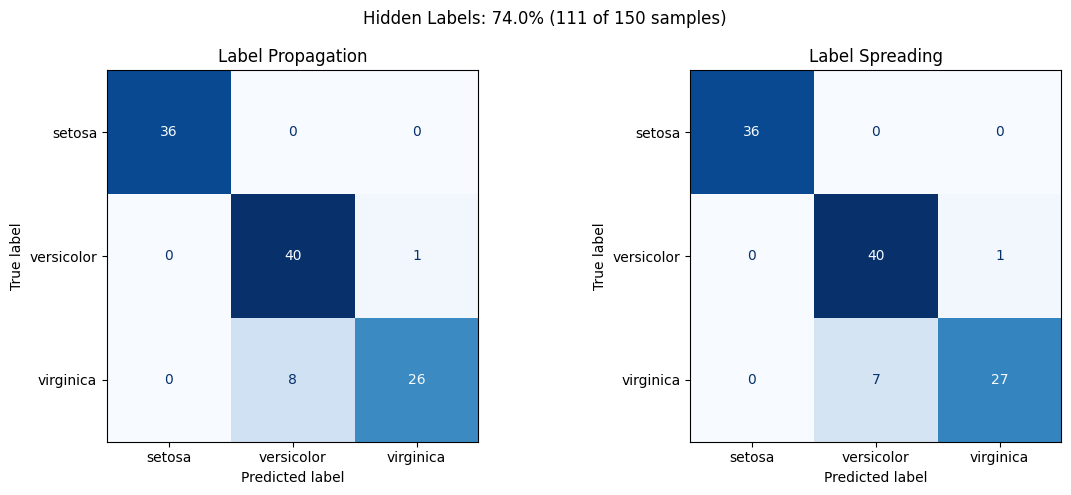

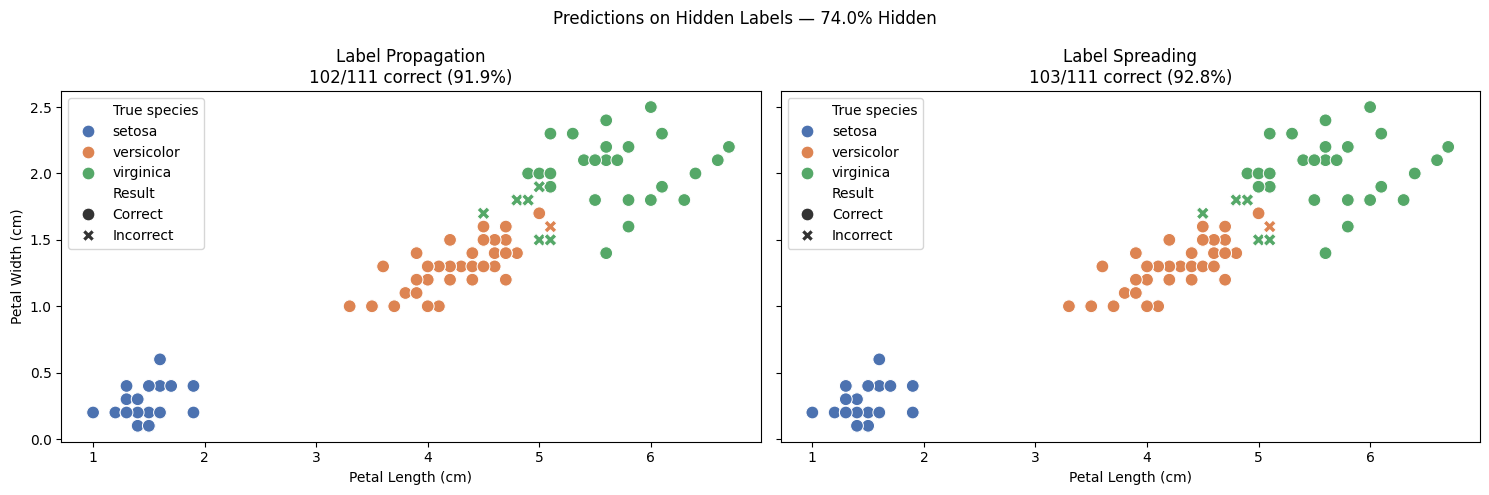

In [9]:
plot_confusion_matrices(
    true_labels=iris.target,
    hidden=random_unlabeled_samples,
    algorithm_one_predictions=predicted_labels_lp,
    algorithm_two_predictions=predicted_labels_ls,
    algorithm_one_name='Label Propagation',
    algorithm_two_name='Label Spreading',
    class_names=iris.target_names,
)

plot_prediction_results(
    iris=iris,
    hidden=random_unlabeled_samples,
    algorithm_one_predictions=predicted_labels_lp,
    algorithm_two_predictions=predicted_labels_ls,
    algorithm_one_name='Label Propagation',
    algorithm_two_name='Label Spreading',
)

<h1>Model hyperparameter optimisation</h1>

This extension tunes **only Label Propagation's `n_neighbors`**, keeping
`kernel="knn"` fixed. It does not tune Label Spreading or the RBF kernel.

Stratified cross-validation temporarily hides some of the **39 known labels**.
Every fold still uses all measurements, but validation labels are withheld
during fitting. The original 111 hidden labels are never used for parameter
selection.

Candidates with invalid validation probabilities are excluded. The highest
mean validation accuracy wins; ties favour the smaller neighbour count.
We then refit using all originally known labels and evaluate recovery of the
original hidden labels. With so few known labels, results can vary across splits.

In [10]:
known_indices = np.flatnonzero(un_labelled != -1)
known_labels = un_labelled[known_indices]

# Each class needs at least one example in each validation fold.
_, class_counts = np.unique(known_labels, return_counts=True)
n_splits = min(5, int(class_counts.min()))

if n_splits < 2:
    raise ValueError("Too few known labels per class for stratified validation.")

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42,
)

results = []

for k in [3, 5, 7, 9, 11, 15]:
    fold_scores = []

    for _, validation_positions in cv.split(known_indices, known_labels):
        validation_indices = known_indices[validation_positions]

        # Hide validation labels as well as the originally hidden labels.
        training_labels = un_labelled.copy()
        training_labels[validation_indices] = -1

        candidate = LabelPropagation(
            kernel="knn",
            n_neighbors=k,
            max_iter=1000,
        )
        candidate.fit(iris.data, training_labels)

        # Check probabilities before converting them into predicted classes.
        with np.errstate(divide="ignore", invalid="ignore"):
            probabilities = candidate.predict_proba(
                iris.data[validation_indices]
            )

        if not np.isfinite(probabilities).all():
            print(f"Skipping k={k}: invalid probabilities in a validation fold.")
            fold_scores.append(np.nan)
            break

        validation_predictions = candidate.classes_[
            probabilities.argmax(axis=1)
        ]

        fold_scores.append(accuracy_score(
            known_labels[validation_positions],
            validation_predictions,
        ))

    results.append({
        "n_neighbors": k,
        "mean_validation_accuracy": np.mean(fold_scores),
        "std_validation_accuracy": np.std(fold_scores),
    })

results_df = (
    pd.DataFrame(results)
    .dropna(subset=["mean_validation_accuracy"])
    .sort_values(
        ["mean_validation_accuracy", "n_neighbors"],
        ascending=[False, True],
    )
)

if results_df.empty:
    raise ValueError("No candidate produced valid probabilities in every fold.")

display_table(results_df, formats={
    'mean_validation_accuracy': '{:.3f}',
    'std_validation_accuracy': '{:.3f}',
})

best_k = int(results_df.iloc[0]["n_neighbors"])
print(f"Selected n_neighbors: {best_k}")

# Refit separately so the baseline model remains available.
tuned_model = LabelPropagation(
    kernel="knn",
    n_neighbors=best_k,
    max_iter=1000,
)
tuned_model.fit(iris.data, un_labelled)

# Evaluate on the original hidden labels only after choosing k.
hidden = un_labelled == -1
predicted_labels_tuned = checked_predictions(tuned_model, iris.data[hidden])

print(
    f"Hidden-label accuracy: "
    f"{accuracy_score(iris.target[hidden], predicted_labels_tuned):.1%}"
)

Skipping k=3: invalid probabilities in a validation fold.


n_neighbors,mean_validation_accuracy,std_validation_accuracy
5,0.975,0.050
11,0.975,0.050
7,0.950,0.061
9,0.950,0.061
15,0.950,0.061


Selected n_neighbors: 5
Hidden-label accuracy: 91.9%


<h1>What did we learn?</h1>

- **Baseline Label Propagation recovered 102 of 111 hidden labels (91.9%).**
  All setosa predictions were correct. Eight virginica flowers were predicted
  as versicolor, and one versicolor flower was predicted as virginica.
- **Graph settings matter.** The KNN baseline uses `n_neighbors=5`; the
  Label Spreading baseline uses RBF. Their 91.9% versus 92.8% scores therefore
  compare configurations, not just the two algorithms.
- **Tune using known labels, not evaluation labels.** Cross-validation selects
  `n_neighbors` by temporarily withholding some known labels. In the seeded
  run, 5 and 11 tied at 97.5% mean validation accuracy; the smaller value, 5,
  was selected. Hidden-label accuracy remained 91.9%.
- **Check probabilities before scoring.** The candidate with 3 neighbours
  produced invalid validation probabilities and was excluded. Disconnected
  regions without reachable label information can cause this problem.
- **These are transductive results.** The models used all flowers' measurements
  during fitting. An independent test set would be needed to assess entirely
  unseen flowers. These results describe one seeded run, not a general ranking.